# A system of your own: adding numbers

A system is a **table**: agents, and a rule for each pair that can meet. This notebook builds one from nothing, for unary numbers: `zero`, `succ`, and addition.

Start with an empty table.

In [1]:
%system new

0 agents, 0 rules, without signs; 0 problems


## Agents

Each port gets a sign: `+` for an output and `-` for an input, the principal port first.

- `zero` is a value: its one port is an output.
- `succ` is a value holding a number: an output, and an input for the number it is one more than.
- `add` is a consumer. Its principal port is an input, waiting for its first number. Then come an input for the second number and an output for the sum.

In [2]:
agent zero +
agent succ + -
agent add  - - +

3 agents, 0 rules, with signs; 2 problems
  no rule for add >< succ
  no rule for add >< zero


The check complains, rightly: `add` can meet `zero` and `succ`, and there is no rule for either.

## Rules

Zero plus `y` is `y`. One more than `x`, plus `y`, is one more than `x` plus `y`.

In [3]:
rule add (y r) >< zero
  => r = y
  count add

rule add (y r) >< succ (x)
  => r = succ (s); x = add (y s)
  count add

3 agents, 2 rules, with signs; 0 problems


No problems. The check has confirmed that each rule keeps its pair's free ports, and that every wire a rule makes joins an output to an input. With that, in a net wired by the signs (the kernel does not check the nets you type), the only principal ports that can ever meet are a consumer's and a value's, and each such pair has a rule.

It has *not* confirmed that the rules are the right ones. Only running them shows that.

## Two plus one

schedule: rounds


trace: on


the net:


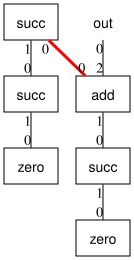

after round 1:


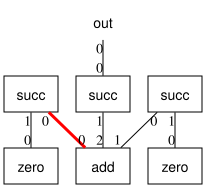

after round 2:


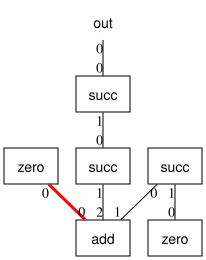

after round 3:


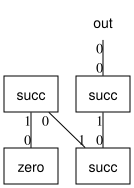

stopped: no active pair is left (normal); 3 interactions, in 3 rounds, the widest of 1; 0 active pairs left; add 3


In [4]:
%schedule rounds
%trace on
succ (succ (zero)) = add (succ (zero) out)

`out` is joined to three `succ`s and a `zero`: three.

Each round had one active pair. Addition this way is sequential: `add` walks down its first number one `succ` at a time.

## A rule that is typed and wrong

Change the first rule so that zero plus `y` is zero: the other number is thrown away, which takes an eraser and its two rules. The check cannot know that this is not what addition means.

In [5]:
%system new
agent zero +
agent succ + -
agent add  - - +
agent era  -

0 agents, 0 rules, without signs; 0 problems


4 agents, 0 rules, with signs; 4 problems
  no rule for add >< succ
  no rule for add >< zero
  no rule for era >< succ
  no rule for era >< zero


In [6]:
rule add (y r) >< zero
  => r = zero; y = era
  count add

rule add (y r) >< succ (x)
  => r = succ (s); x = add (y s)
  count add

rule era >< zero
  => nothing
  count erase

rule era >< succ (x)
  => x = era
  count erase

4 agents, 4 rules, with signs; 0 problems


trace: off


the net:


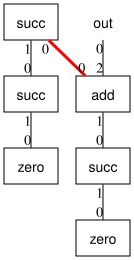

stopped: no active pair is left (normal); 5 interactions, in 5 rounds, the widest of 1; 0 active pairs left; add 3, erase 2


what is left:


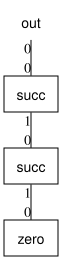

In [7]:
%trace off
succ (succ (zero)) = add (succ (zero) out)

No problems reported, and two plus one is two. Signs keep a system from getting stuck; they do not make it mean what you intended.